# Optimization Demo (Replay BO)

This notebook demonstrates an end-to-end **optimization workflow** using the current OOP boundaries:
- `Dataset`: `BCLFDataset` (data container)
- `Simulator`: `ReplaySimulator` (offline oracle from existing data)
- `Objective`: maximize passband mean S21 (single-metric objective)
- `Surrogate`: GP/ANN/BNN model
- `Acquisition`: UCB/EI
- `Optimizer`: `ReplayOptimizer` (controller)
- `Recorder`: save JSON/CSV run artifacts


In [1]:
from pathlib import Path
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

NOTEBOOK_DIR = Path.cwd()
REPO_ROOT = NOTEBOOK_DIR if (NOTEBOOK_DIR / 'src').exists() else NOTEBOOK_DIR.parent
os.chdir(REPO_ROOT)
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))

from optimization import (
    ANNSurrogate,
    BCLFDataset,
    BNNSurrogate,
    EIAcquisition,
    ExperimentRecorder,
    GPSurrogate,
    BandMaxMetric,
    BandMeanMetric,
    GreaterEqualConstraint,
    LessEqualConstraint,
    MaximizeMetric,
    ObjectiveFunction,
    ReplayOptimizer,
    ReplaySimulator,
    UCBAcquisition,
)

print(f'Repo root: {REPO_ROOT}')


Repo root: /home/zhanghf/projects/vector


In [2]:
# Demo config (latest setting)
CONFIG_PATH = Path('configs/filter_bnn_online_uaw_uaw.yaml')
DATASET_PATH = Path('data/filter_bnn_online_uaw_uaw_dataset.pkl')
RUN_ID = 'optimization_demo_latest_nb'
BUDGET = 40
N_INIT = 0
SEED = 1

SURROGATE_NAME = 'gp'   # 'gp' | 'ann' | 'bnn'
ACQ_NAME = 'ucb'        # 'ucb' | 'ei'
UCB_BETA = 6.0
EI_XI = 0.20

with CONFIG_PATH.open('r', encoding='utf-8') as f:
    cfg = yaml.safe_load(f)
freq_cfg = cfg['data']['freqs']
freqs = np.arange(freq_cfg['min'], freq_cfg['max'], freq_cfg['step'], dtype=float)
print('freq points=', len(freqs), 'freq range=', (freqs.min(), freqs.max()))


freq points= 401 freq range= (np.float64(3500000000.0), np.float64(8700000000.0))


In [3]:
# Build core components
dataset = BCLFDataset.from_pickle(DATASET_PATH, freqs=freqs)
simulator = ReplaySimulator(dataset=dataset)

# Simple BCLF Objective
passband = (5.2e9, 5.9e9)
lower_stopband = (3.6e9, 4.8e9)
upper_stopband = (6.5e9, 8.7e9)

objective = ObjectiveFunction(
    terms=[
        MaximizeMetric(
            name="maximize_passband_s21_mean",
            metric=BandMeanMetric("S21", passband),
        ),
    ],
    constraints=[
        GreaterEqualConstraint(
            name="passband_s21_mean_geq_minus_5db",
            metric=BandMeanMetric("S21", passband),
            lower_bound=-5.0,
        ),
        LessEqualConstraint(
            name="passband_s11_max_leq_minus_10db",
            metric=BandMaxMetric("S11", passband),
            upper_bound=-10.0,
        ),
        LessEqualConstraint(
            name="lower_stopband_s21_max_leq_minus_25db",
            metric=BandMaxMetric("S21", lower_stopband),
            upper_bound=-25.0,
        ),
        LessEqualConstraint(
            name="upper_stopband_s21_max_leq_minus_25db",
            metric=BandMaxMetric("S21", upper_stopband),
            upper_bound=-25.0,
        ),
    ],
    penalty_weight=100.0,
)

if SURROGATE_NAME == 'gp':
    surrogate = GPSurrogate(length_scale=1.0, noise_variance=1e-8)
elif SURROGATE_NAME == 'ann':
    surrogate = ANNSurrogate(epochs=120, seed=SEED)
elif SURROGATE_NAME == 'bnn':
    surrogate = BNNSurrogate(epochs=120, seed=SEED, mc_samples=16)
else:
    raise ValueError(f'Unsupported SURROGATE_NAME={SURROGATE_NAME}')

if ACQ_NAME == 'ucb':
    acquisition = UCBAcquisition(beta=UCB_BETA)
elif ACQ_NAME == 'ei':
    acquisition = EIAcquisition(xi=EI_XI)
else:
    raise ValueError(f'Unsupported ACQ_NAME={ACQ_NAME}')

initial_indices = [] if N_INIT == 0 else dataset.default_train_indices[:N_INIT]
candidate_indices = list(range(len(dataset)))

print('dataset_size=', len(dataset))
print('initial_indices=', initial_indices)
print('candidate_count=', len(candidate_indices))
print('objective=', objective.describe())


dataset_size= 1323
initial_indices= []
candidate_count= 1323
objective= {'type': 'objective_function', 'minimize': True, 'penalty_weight': 100.0, 'terms': [{'name': 'maximize_passband_s21_mean', 'kind': 'MaximizeMetric', 'metric': 's21_mean_5200000000_5900000000', 'weight': 1.0}], 'constraints': [{'name': 'passband_s21_mean_geq_minus_5db', 'kind': 'GreaterEqualConstraint', 'metric': 's21_mean_5200000000_5900000000'}, {'name': 'passband_s11_max_leq_minus_10db', 'kind': 'LessEqualConstraint', 'metric': 's11_max_5200000000_5900000000'}, {'name': 'lower_stopband_s21_max_leq_minus_25db', 'kind': 'LessEqualConstraint', 'metric': 's21_max_3600000000_4800000000'}, {'name': 'upper_stopband_s21_max_leq_minus_25db', 'kind': 'LessEqualConstraint', 'metric': 's21_max_6500000000_8700000000'}]}


In [4]:
optimizer = ReplayOptimizer(
    dataset=dataset,
    simulator=simulator,
    objective=objective,
    surrogate=surrogate,
    acquisition=acquisition,
    recorder=ExperimentRecorder(output_dir=Path('experiments/bo_replay')),
    initial_indices=initial_indices,
    candidate_indices=candidate_indices,
    test_indices=dataset.default_test_indices,
    budget=BUDGET,
    retrain_every=1,
    n_init=N_INIT,
    seed=SEED,
    run_id=RUN_ID,
)

result = optimizer.run()

print('run_id=', result.run_id)
print('trials=', len(result.history))
print('best_index=', result.state.best_index)
print('best_objective=', result.state.best_objective)
print('sim_calls=', simulator.num_calls, 'success=', simulator.num_success, 'failed=', simulator.num_failures)
print('json=', result.recorder_output.json_path)
print('csv=', result.recorder_output.csv_path)


run_id= optimization_demo_latest_nb
trials= 40
best_index= 476
best_objective= 658.8415314654194
sim_calls= 40 success= 40 failed= 0
json= experiments/bo_replay/optimization_demo_latest_nb.json
csv= experiments/bo_replay/optimization_demo_latest_nb.csv


In [5]:
history_df = pd.DataFrame(result.history)
display_cols = ['iteration', 'phase', 'dataset_index', 'objective', 'best_so_far', 'acquisition_score']
history_df[display_cols].head(20)


,iteration,phase,dataset_index,objective,best_so_far,acquisition_score
0,0,bo,626,977.830388,977.830388,NaN
1,1,bo,596,752.491381,752.491381,-975.567716
2,2,bo,688,747.087181,747.087181,-792.053065
3,3,bo,565,791.199067,747.087181,-776.021349
4,4,bo,735,752.109438,747.087181,-783.929536
5,5,bo,734,801.802143,747.087181,-780.126765
6,6,bo,113,732.721108,732.721108,-782.352926
7,7,bo,288,832.635491,732.721108,-776.509024
8,8,bo,9,755.441771,732.721108,-791.804643
9,9,bo,832,747.767102,732.721108,-768.130509


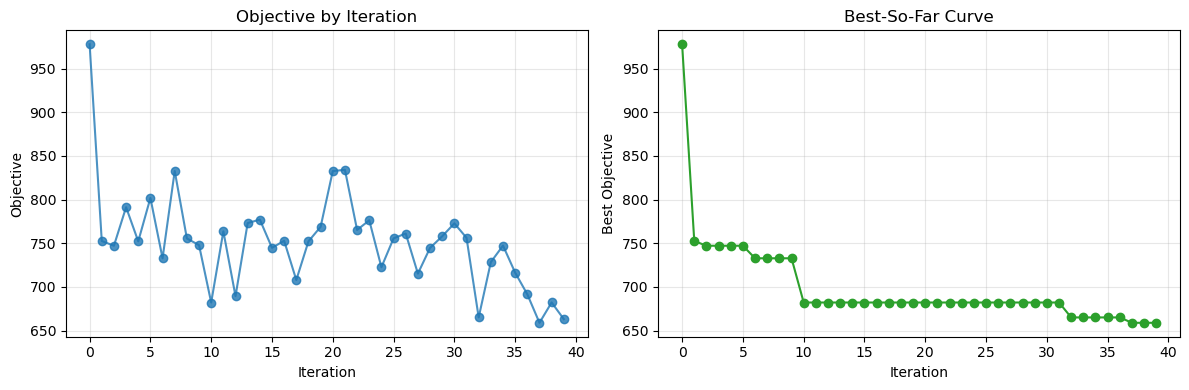

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df['iteration'], history_df['objective'], marker='o', alpha=0.8)
axes[0].set_title('Objective by Iteration')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Objective')
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_df['iteration'], history_df['best_so_far'], marker='o', color='tab:green')
axes[1].set_title('Best-So-Far Curve')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Best Objective')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


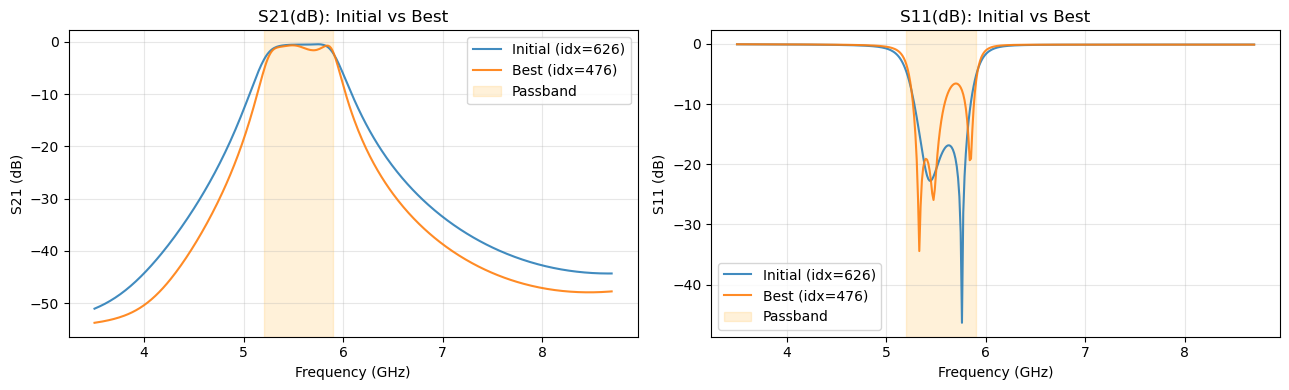

Initial objective=977.8304, Best objective=658.8415


In [7]:
# Compare initial sampled point vs best point in frequency response
if history_df.empty:
    raise ValueError('Empty history; nothing to plot')

initial_row = history_df.iloc[0]
best_row = history_df.loc[history_df['objective'].idxmin()]

init_idx = int(initial_row['dataset_index'])
best_idx = int(best_row['dataset_index'])

_, s_init = dataset.get_response_by_geometry(dataset.get_geometry(init_idx))
_, s_best = dataset.get_response_by_geometry(dataset.get_geometry(best_idx))

s11_init_db = 20.0 * np.log10(np.maximum(np.abs(s_init[0, 0]), 1e-12))
s21_init_db = 20.0 * np.log10(np.maximum(np.abs(s_init[1, 0]), 1e-12))
s11_best_db = 20.0 * np.log10(np.maximum(np.abs(s_best[0, 0]), 1e-12))
s21_best_db = 20.0 * np.log10(np.maximum(np.abs(s_best[1, 0]), 1e-12))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
freq_ghz = freqs / 1e9
pb = passband if "passband" in globals() else (5.2e9, 5.9e9)
pb0, pb1 = pb[0] / 1e9, pb[1] / 1e9

axes[0].plot(freq_ghz, s21_init_db, label=f'Initial (idx={init_idx})', alpha=0.85)
axes[0].plot(freq_ghz, s21_best_db, label=f'Best (idx={best_idx})', alpha=0.9)
axes[0].axvspan(pb0, pb1, color='orange', alpha=0.15, label='Passband')
axes[0].set_title('S21(dB): Initial vs Best')
axes[0].set_xlabel('Frequency (GHz)')
axes[0].set_ylabel('S21 (dB)')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(freq_ghz, s11_init_db, label=f'Initial (idx={init_idx})', alpha=0.85)
axes[1].plot(freq_ghz, s11_best_db, label=f'Best (idx={best_idx})', alpha=0.9)
axes[1].axvspan(pb0, pb1, color='orange', alpha=0.15, label='Passband')
axes[1].set_title('S11(dB): Initial vs Best')
axes[1].set_xlabel('Frequency (GHz)')
axes[1].set_ylabel('S11 (dB)')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Initial objective={float(initial_row['objective']):.4f}, Best objective={float(best_row['objective']):.4f}")


In [8]:
# Final result table: expand best trial metrics
best_row = history_df.loc[history_df['objective'].idxmin()]
best_metrics = pd.Series(best_row['metrics'], name='value').to_frame()
best_overview = pd.DataFrame([{
    'run_id': result.run_id,
    'best_iteration': int(best_row['iteration']),
    'best_index': int(best_row['dataset_index']),
    'best_case_id': best_row['case_id'],
    'best_objective': float(best_row['objective']),
    'sim_calls': simulator.num_calls,
}])

print('Best overview:')
display(best_overview)
print('Best metrics:')
display(best_metrics)


Best overview:


,run_id,best_iteration,best_index,best_case_id,best_objective,sim_calls
0,optimization_demo_latest_nb,37,476,476,658.841531,40


Best metrics:


,value
s21_mean_5200000000_5900000000,-1.403785
s11_max_5200000000_5900000000,-3.425623
s21_max_3600000000_4800000000,-28.270429
s21_max_6500000000_8700000000,-29.138777
raw_objective,1.403785
total_positive_violation,6.574377
penalty,657.437747


In [9]:
# Persisted payload summary + final best metrics from JSON
with Path(result.recorder_output.json_path).open('r', encoding='utf-8') as f:
    payload = json.load(f)

summary_df = pd.DataFrame([payload['summary']])
best_trial_payload = max(payload['trials'], key=lambda row: float(row['objective']))
best_metrics_payload = pd.Series(best_trial_payload['metrics'], name='value').to_frame()

display(summary_df)
display(best_metrics_payload)


,num_trials,best_objective,best_dataset_index,best_case_id
0,40,658.841531,476,476


,value
s21_mean_5200000000_5900000000,-0.936473
s11_max_5200000000_5900000000,-4.631172
s21_max_3600000000_4800000000,-21.684827
s21_max_6500000000_8700000000,-23.915061
raw_objective,0.936473
total_positive_violation,9.768939
penalty,976.893915
